# TP1 : descente de gradient à la main sur des contrats d'assurance auto

Objectif : refaire à la main ce que font `nn.Linear` et l'optimiseur de la démo 1. Un modèle linéaire prédit le coefficient de bonus-malus d'un contrat d'assurance auto à partir de trois informations : l'âge du conducteur, l'âge du véhicule et le nombre de sinistres. Vous observez d'abord ce qui se passe quand on oublie de remettre les gradients à zéro, puis vous corrigez la boucle.

L'énoncé complet, avec les critères de réussite, est dans `enonce.md`.

*Complétez les cellules marquées `# TODO`, dans l'ordre.*

## Installation

Cette cellule écrit `requirements-colab.txt` (les versions de la formation, alignées sur le runtime Colab), puis l'installe avec uv. Les paquets déjà présents à la bonne version ne sont pas réinstallés. Hors de Colab, elle n'installe rien : l'environnement uv du projet contient déjà ces versions.

In [1]:
import importlib.util
from pathlib import Path

Path("requirements-colab.txt").write_text("""torch==2.11.0
torchvision==0.26.0
numpy==2.1.3
matplotlib==3.10.0
pillow==11.3.0
scikit-learn==1.6.1
pandas==2.2.2; python_version < "3.13"
pandas==2.2.3; python_version >= "3.13"
pyarrow>=14
tensorboard==2.21.0
onnx==1.23.0
onnxruntime==1.30.0
onnxscript==0.7.2
torchserve==0.12.0
torch-model-archiver==0.12.0
""")

if importlib.util.find_spec("google.colab") is not None:
    %pip install -q --progress-bar off uv
    !uv pip install --system -q -r requirements-colab.txt
else:
    print("Hors Colab : environnement uv du projet, rien à installer.")

## Préparation (fournie)

**Données** : freMTPL2freq, contrats d'assurance responsabilité civile automobile en France (OpenML, licence CC0). Pour chaque contrat : âge du conducteur, âge du véhicule, nombre de sinistres, et le coefficient de bonus-malus à prédire (de 50 à 230 ; plus il est élevé, plus le conducteur est considéré comme risqué).

In [2]:
def charger_contrats(n=5000, seed=0):
    """Contrats d'assurance auto tirés au hasard, dans une table pandas aux colonnes renommées en français."""
    from sklearn.datasets import fetch_openml

    table = fetch_openml(data_id=41214, as_frame=True, parser="pandas").frame
    table = table.sample(n=n, random_state=seed).reset_index(drop=True)
    table = table.rename(columns={
        "Exposure": "exposition", "DrivAge": "age_conducteur", "VehAge": "age_vehicule",
        "VehPower": "puissance", "VehGas": "carburant", "Density": "densite", "Region": "region",
        "ClaimNb": "nb_sinistres", "BonusMalus": "bonus_malus",
    })
    table["carburant"] = table["carburant"].str.strip("'")
    colonnes = ["age_conducteur", "age_vehicule", "nb_sinistres", "exposition", "puissance", "carburant",
                "densite", "region", "bonus_malus"]
    return table[colonnes]

In [3]:
table = charger_contrats(n=5000)
table.head()

,age_conducteur,age_vehicule,nb_sinistres,exposition,puissance,carburant,densite,region,bonus_malus
0,55,18,0,1.00,7,Diesel,43,R24,50
1,40,16,0,0.08,4,Regular,1765,R31,55
2,72,13,0,1.00,4,Regular,49,R24,50
3,39,0,0,0.12,10,Regular,528,R93,50
4,57,10,0,0.23,7,Diesel,113,R91,50


## Étape 0 : découvrir les données (fournie)

Exécutez les cellules, puis répondez aux questions.

In [4]:
table[["age_conducteur", "age_vehicule", "nb_sinistres", "bonus_malus"]].describe().round(1)

,age_conducteur,age_vehicule,nb_sinistres,bonus_malus
count,5000.0,5000.0,5000.0,5000.0
mean,45.5,7.0,0.0,59.8
std,14.2,5.6,0.2,15.6
min,18.0,0.0,0.0,50.0
25%,34.0,2.0,0.0,50.0
50%,44.0,6.0,0.0,50.0
75%,55.0,11.0,0.0,64.0
max,96.0,50.0,3.0,196.0


In [5]:
print(table["nb_sinistres"].value_counts())

nb_sinistres
0    4762
1     227
2      10
3       1
Name: count, dtype: int64


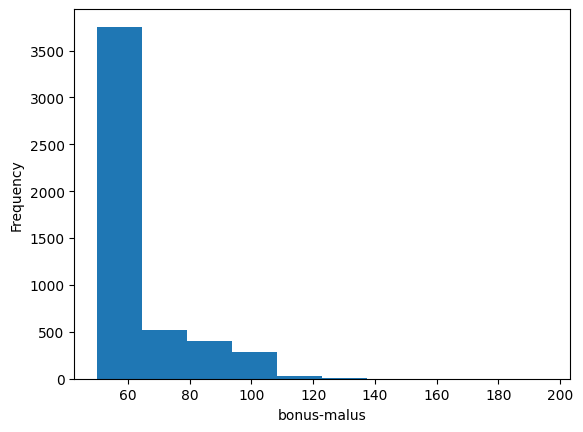

In [7]:
import matplotlib.pyplot as plt

table["bonus_malus"].plot(kind="hist", bins=10, xlabel="bonus-malus")
plt.show()

In [10]:
table.groupby("nb_sinistres")["bonus_malus"].mean().round(2)
# .plot(kind="bar", ylabel="bonus-malus moyen")
# plt.show()

,bonus_malus
nb_sinistres,
0,59.59
1,63.22
2,68.00
3,76.00


Questions : quelle valeur de bonus-malus est la plus fréquente ? Le bonus-malus moyen augmente-t-il avec le nombre de sinistres ?

*Vos réponses :*

## Du tableau au tenseur (fourni)

Les trois informations deviennent un tenseur `x` de 5000 lignes et 3 colonnes, et la cible un tenseur `y`. Comme dans la démo 1, on remet les colonnes à la même échelle : chacune est centrée et réduite (moyenne 0, écart-type 1).

In [ ]:
import torch

colonnes = ["age_conducteur", "age_vehicule", "nb_sinistres"]
features = torch.tensor(table[colonnes].to_numpy(dtype="float32"))
x = (features - features.mean(dim=0)) / features.std(dim=0)
y = torch.tensor(table["bonus_malus"].to_numpy(dtype="float32"))
print(x.shape, y.shape)

## Étape 1 : le modèle et l'erreur

Le modèle linéaire : `x @ w + b`, un poids par colonne plus un biais. L'erreur : la moyenne des carrés des écarts. Chaque réponse tient en une ligne.

In [ ]:
def model(x, w, b):
    # TODO : le produit matriciel de x par w, plus b
    ...


def loss_fn(prediction, y):
    # TODO : la moyenne des carrés des écarts entre prediction et y
    ...

In [ ]:
w = torch.zeros(3, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
assert model(x, w, b).shape == (5000,), "une prédiction par contrat"
print("erreur de départ :", loss_fn(model(x, w, b), y).item())

## Étape 2 : deux backward de suite

Ajoutez l'appel qui calcule les gradients. La boucle le fait deux fois, sans remise à zéro. Prédisez le second gradient avant d'exécuter.

In [ ]:
w = torch.zeros(3, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
for appel in range(2):
    loss = loss_fn(model(x, w, b), y)
    # TODO : calculer les gradients de loss
    print(f"après le backward n°{appel + 1} :", w.grad)

## Étape 3 : une boucle sans remise à zéro (fournie)

Cette boucle de descente de gradient oublie de remettre les gradients à zéro. Exécutez-la et regardez l'erreur.

In [ ]:
def entrainer_sans_remise_a_zero(n_iter=100, lr=0.1):
    w = torch.zeros(3, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    erreurs = []
    for _ in range(n_iter):
        loss = loss_fn(model(x, w, b), y)
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        erreurs.append(loss.item())
    return erreurs

In [ ]:
plt.plot(entrainer_sans_remise_a_zero())
plt.xlabel("itération")
plt.ylabel("erreur")
plt.show()

Question : l'erreur baisse-t-elle régulièrement ? Pourquoi ?

*Votre réponse :*

## Étape 4 : la boucle corrigée

Complétez les deux TODO : la remise à zéro des gradients, puis la mise à jour de `w` et `b` (un petit pas à l'opposé du gradient, sous `torch.no_grad()`).

In [ ]:
def entrainer(n_iter=300, lr=0.1):
    w = torch.zeros(3, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    erreurs = []
    for _ in range(n_iter):
        loss = loss_fn(model(x, w, b), y)
        if w.grad is not None:
            # TODO : remettre w.grad et b.grad à zéro
            ...
        loss.backward()
        with torch.no_grad():
            # TODO : w -= lr * w.grad, et de même pour b
            ...
        erreurs.append(loss.item())
    return w, b, erreurs

In [ ]:
w, b, erreurs = entrainer()
print("w =", w.detach(), " b =", b.detach(), " erreur finale :", round(erreurs[-1], 1))
plt.plot(erreurs)
plt.xlabel("itération")
plt.ylabel("erreur")
plt.show()
assert erreurs[-1] < erreurs[0] / 10, "l'erreur devrait avoir fortement baissé"

## Étape 5 : vérifier avec la solution exacte (fournie)

Pour un modèle linéaire, il existe une solution exacte, celle des moindres carrés, que calcule `torch.linalg.lstsq`. Vos poids sont-ils les mêmes ?

In [ ]:
A = torch.cat([x, torch.ones(len(x), 1)], dim=1)
exacte = torch.linalg.lstsq(A, y.unsqueeze(1)).solution.squeeze()
descente = torch.cat([w.detach(), b.detach()])
print("solution exacte     :", exacte)
print("descente de gradient:", descente)
assert torch.allclose(descente, exacte, atol=1e-2), "les deux solutions devraient coïncider"

## Bonus

**B1. Avec un optimiseur.** Refaites l'entraînement avec `torch.optim.SGD`, comme dans la démo 1 : `optimizer.zero_grad()` et `optimizer.step()` remplacent la remise à zéro et la mise à jour. Vérifiez que vous obtenez les mêmes poids.

In [ ]:
# TODO : la même boucle avec torch.optim.SGD

**B2. Le learning rate.** Relancez `entrainer` avec `lr=1.5`, puis avec `lr=0.001`. Que devient l'erreur ?

In [ ]:
# TODO : entrainer(lr=1.5), puis entrainer(lr=0.001), et comparer les erreurs